# Signed Networks
In this chapter we will:

1. Define signed networks
2. Explore how and why signed networks are special
3. Translate basic network measures to signed networks 

*Acknowledgement: This chapter relies on \_\_\_\_\_\_\_\_\_\_ from \_\_\_\_\_\_\_\_\_\_.*


fit in null models
what makes it hard
signed link prediction

------------

## Plan

**The problem:** Regular (unsigned) networks use edges to denote the relationships that exist between nodes. However, while these edges indicate the presence of a relationship, they provide no way to characterize *opposite* relations. In contrast, many real networks have nodes with opposing relations,  or relations characterized by *conflict*. For example, in social networks people often have both friendly relations and antagonistic relations. Countries can be allies or enemies. Neurons can excite or inhibit one another $^{2}$. 

This conflict is denoted by negative links in a network. Negative links do more than just include information opposing relationships: the interaction of positive and negative links fundamentally impacts the structure and dynamics of the underlying network $^{3}$. Thus, examining only positive links or only negative links misses a vital component of complexity.

Unfortunately, the inclusion of negative links introduces mathematical complications for many of the measures traditionally used to analyze networks, such as degree distribution, clustering, path distance, and community detection $^{2}$. It also creates necessity for new measures, such as balance. In this lesson, we will discuss the utility of signed networks, explore how many of these measures are translated to analyze signed networks, and acknowledge the gaps and limitations that still remain in the emerging field. 

**Table of contents:**

1. **Introduction to Signed Networks**
    - What are signed networks?
    - Properties of Signed Networks
    - Basic notation
    - Applications of signed networks 

2. **Basic Network Measures**:
    - Overview of basic challenges for measures of signed networks
    - Start with degree distribution: look at the differences through code/examples
    - Look at clustering and implement sign-based clustering
    - Briefly touch on how the measures for clustering, centrality, and community detection differ (maybe implement in advanced topics section?)

3. **Balance**: 
    - A brief history of Heidarian and Hararian balance
    - Practical Exercise: 
        - Hararian theorem: for a small network, code that looks at every path
        - *Your turn*: Implement Hararian Theorem 1
    - Code implementation of degree of balance 

4. **Limitations**:
    - Discuss current challenges with signed networks
    - Identify major gaps in the literature

5. **Advanced Topics**

6. **References**

*There are five major sections, and about eight weeks to complete them! My plan is to work on roughly one section for two weeks from now until the end of the semester. The introduction is already underway. The limitations section is straightforward, so that one will be completed last and only require one week. The bulk of the effort will go towards sections 2 and 3, and any leftover time will be used for expanding on the advanced topics section, especially community detection.*

__________

In [1]:
# import your packages! and whatever else that's basic that you need
# If you need a package that isn't in our course environment (cmns-core), say which one
# and how to install it, here at the top.
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
rc('axes', fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')
rc('axes', axisbelow=True)

## Signed Networks: An Introduction

#### The hook: Some type of exciting example of signed networks

Networks are great, because we can study the interactions between entities.

But- but- not all interactions are positive, and not all nodes are friends! How do we represent conflict?!

<br>

<img src="https://cdn1.faroutmagazine.co.uk/uploads/1/2023/06/Bruce-Lee-Chuck-Norris-Fight-Far-Out-Magazine-F.jpg" width="600" height="auto">

*Source: [Far Out Magazine](https://faroutmagazine.co.uk/bruce-lee-illegally-fought-chuck-norris/)*

#### Signed networks!

------------

### What is a signed network?

A signed network is a network with both positive and negative edges:

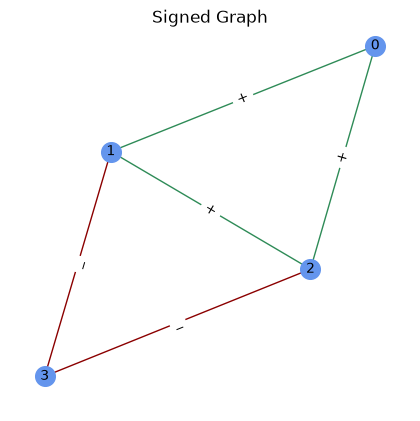

In [37]:
G = nx.Graph()
G.add_nodes_from([0, 1, 2, 3])
signed_edges = [
    (0, 1, {"sign": "+"}),
    (0, 2, {"sign": "+"}),
    (1, 2, {"sign": "+"}),
    (2, 3, {"sign": "_"}),
    (3, 1, {"sign": "_"}),
]
G.add_edges_from(signed_edges)

# Visualize it
pos = nx.spring_layout(G)
edge_colors = [
    "seagreen" if attrs["sign"] == "+" else "darkred" for u, v, attrs in G.edges(data=True)
]
plt.figure(figsize=(4, 4))
nx.draw(
    G,
    with_labels=True,
    node_color="cornflowerblue",
    edge_color=edge_colors,
    node_size=200,
    font_size=10,
    pos=pos
)

nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'sign'))

plt.title("Signed Graph", y=.95)
plt.show()

We want to examine signed networks just like we do regular networks, while also taking advantage of the extra information and considering the context that signs give us. 

So, this lesson tries to do that.

And, idk, some more overview of signed networks!

### Properties of Signed Networks

What is the degree of node 3 in this network?

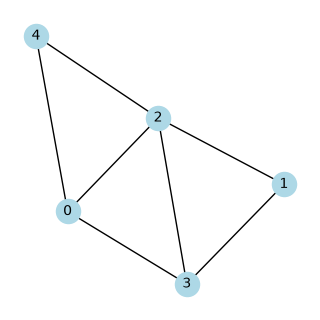

<br><br>

It's not a trick question- it's three! But what about this network? <br><br>

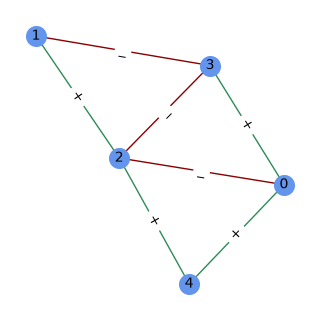

Is it one? Three? Maybe -1?

Clearly, basic network measures are not so straightforward when we incorporate signs! 

##### Four main challenges: 

1. **Absolute vs net metrics**  <br><br>
     $1 + |-1| + |-1| = 3$  <br>  $1 + (-1) + (-1) = -1$ <br><br>
     *Context matters in choosing the right one!*
    <br><br>
2. **Shortest-path distance**: negative edges violates the non-negativity metric axiom <br> <br>

    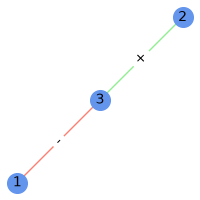

    Shortest path from *Node 1* to *Node 2* is [-1,1]. Sooo.... zero?!
    <br><br>
3. **Perron-Frobenius Theory** <br><br>
    $$
    A = \begin{bmatrix}
    0 & 1 & 1 & 0 \\
    1 & 0 & 1 & -1 \\
    1 & 1 & 0 & -1 \\
    0 & -1 & -1 & 0
    \end{bmatrix}
    $$
 

In [11]:
G = nx.Graph()
G.add_nodes_from([0, 1, 2, 3])
signed_edges = [
    (0, 1, {"sign": 1}),
    (0, 2, {"sign": 1}),
    (1, 2, {"sign": 1}),
    (2, 3, {"sign": -1}),
    (3, 1, {"sign": -1}),
]
G.add_edges_from(signed_edges)
adj_matrix = nx.to_numpy_array(G)
adj_matrix

array([[0., 1., 1., 0.],
       [1., 0., 1., 1.],
       [1., 1., 0., 1.],
       [0., 1., 1., 0.]])

- Must account for both negative and positive edges
- How these influence each other
- Issues with math on signed networs

### Basic Notation

- Adjacency matrix
- Matrices A+ and A-  

### Common Applications 
- Social Networks (where this comes from!)
- Neurons (brain networks)
- Proteins
- Etc


------------

## Basic Network Measures

Signed networks present challenges for many of the traditional measures used to analyze networks. 
Strategies to calculate these measures often generate ill-defined results, describe generalizations relevant to different contexts $^{3}$, or result in loss of valuable information. 

### Degree Distibution

In [ ]:
# Which is the correct degree distribution for this network?
# Show signed networks with degree distribution of positive links, negative links, and counting both links
# How do we calculate degree distribution?
# Describe options and tradeoffs

### Signed Distances

- Explain why signed distances are challenging
- show scary math equation highlighting math challenges

In [ ]:
# Algorithm to implement signed distances
# This should show the challenges

### Other Measures

- Clustering coefficient
- Community detection 
- Maybe other forms of centrality

Briefly describe the challenges and common solutions for each, maybe expand in advanced topic?


------------

## Balance

It matters because it impacts network dynamics! And other reasons. We will discuss all of this. 

### Heidarian Balance

- Taco-bout the history of Heider and his balance theory
- Have a cute diagram of his

### Hararian Balance

- Taco-bout the history of Harar and how he built on Heidar's theory
- Show a cool network that is balanced

#### A network is balanced when....

Show balanced and unbalanced networks

In [ ]:
# code that looks for Hararian balance the slow way

#### What's wrong with this code?

It's slow! And impractical!

Luckily, Hararian has two more theorems that make balance easier to detect. 

- Formula of Theorem 1
- Formula of Theorem 2

### Your turn!

In [ ]:
# implement Hararian Theorem 1 in code 

#### But..... is any real life network ever balanced?

Probably not. 

But balance is still useful for studying signed networks. So... we need a measure that indicates the *amount* of balance in a network. 

### Degree of Balance

- Degree of Balance theorem
- why it's good for actual networks

In [ ]:
# Code for degree of balance - maybe make it a your turn? Don't know

------------

## Limitations

- Things that we still don't really know how to do with signed networks
- Gaps in the literature

------------

## Potential Advanced Topics

- Null models
- Embeddings
- Community detection

_______

## References and further resources:

1. Cartwright, D., & Harary, F. (1956). Structural balance: A generalization of Heider’s theory. Psychological Review, 63(5), 277.
2. Diaz-Diaz, F. (2025). Mathematical analysis of signed networks: Structure and dynamics [PhD Thesis]. Institute of Cross-Disciplinary Physics and Complex Systems, IFISC.
3. Diaz-Diaz, F., Candellone, E., Gonzalez-Casado, M. A., Fraxanet, E., Vendeville, A., Ferri, I., & Teixeira, A. S. (2026). Signed Networks: Theory, methods, and applications (arXiv:2511.17247). arXiv. https://doi.org/10.48550/arXiv.2511.17247
4. Heider, F. (1946). Attitudes and cognitive organization. The Journal of Psychology, 21(1), 107–112.
5. Tang, W., & Zhu, J. (2025). Population-Level Balance in Signed Networks. Journal of the American Statistical Association, 120(550), 751–763. https://doi.org/10.1080/01621459.2024.2356894



(Aim for 10+ useful citations)